# Figure 2 - Potential of mean force, hard-sphere potential

Two-body Monte Carlo simulations with **Faunus** of two rigid antibodies at
amino-acid resolution. One antibody is fixed and the second is moved along z;
the radial distribution function g(r) of the centre-of-mass separation is
recorded and converted to the potential of mean force (PMF) as
`U(r)/kT = -ln[g(r)/g_bulk]`.

Here only excluded volume is included (hard spheres); charge and attraction are
switched off. Three structures are run: `mAb-1` at ionic strengths 7 and 57 mM
and `mAb-2`. Each structure runs in its own sub-directory and the structures
are read from the shared `../pqr_inputs/` folder.

**How to run:** install the environment (`conda env create -f ../environment.yml`),
then run the cells top to bottom. The simulator is called by `run_faunus()`;
edit that function to submit to a cluster instead.

## Import packages

In [1]:
import os
import subprocess
import numpy as np
from jinja2 import Template
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 16, "legend.frameon": True, "figure.figsize": [5, 5],
                     "xtick.major.size": 7, "ytick.major.size": 7, "legend.labelspacing": 1})


## Functions

In [2]:
def create_input(workdir, structure, macro, micro, nstep, nskip):
    """Render the Faunus input (input.yml) for one run from the template below."""
    with open("input.yml", "w") as f:
        return f.write(Input.render(workdir=workdir, structure=structure,
                                    macro=macro, micro=micro, nstep=nstep, nskip=nskip))


def run_faunus(use_state=False):
    """Run Faunus locally in the current run directory.

    Requires `faunus` and `yason.py` on PATH (installed by the conda
    environment, see ../environment.yml). Output goes to `out`, errors to `err`.
    To run on a cluster instead, replace the body of this function with your
    own submission command (e.g. write an sbatch script and call `sbatch`)."""
    state = "--state state.json " if use_state else ""
    cmd = ("set -o pipefail; export OMP_NUM_THREADS=1; "
           f"yason.py input.yml | faunus {state}-v 6 > out 2> err")
    subprocess.run(["bash", "-c", cmd], check=True)


# PMF hard-sphere potential - runs

In [ ]:
# --- Define the working directory ONCE ---
try:
    os.chdir(workdir)
except (NameError, FileNotFoundError):
    workdir = os.getcwd()

workdir = os.getcwd()
#-------------------------------------------

Input = Template("""
temperature: 298.15
geometry: {type: cuboid, length: [300, 300, 2000] }
mcloop: {micro: {{micro}}, macro: {{macro}}}
random: {seed: hardware}
energy:
    - nonbonded:
        cutoff_g2g: 180
        default:
            - hardsphere:
                mixing: arithmetic
                
atomlist:
    - CTR:  {mw: 16.0,  sigma: 3.13, eps: 0.005, q: -1 }
    - HCTR: {mw: 16.0,  sigma: 3.13, eps: 0.005, q: 0 }
    - NTR:  {mw: 14.0,  sigma: 2.99, eps: 0.005, q: 0 }
    - HNTR: {mw: 14.0,  sigma: 2.99, eps: 0.005, q: 1 }
    - ALA:  {mw: 66.0,  sigma: 5.02, eps: 0.005, q: 0 }
    - ILE:  {mw: 102.0, sigma: 5.8,  eps: 0.005, q: 0 }
    - LEU:  {mw: 102.0, sigma: 5.8,  eps: 0.005, q: 0 }
    - MET:  {mw: 122.0, sigma: 6.16, eps: 0.005, q: 0 }
    - PHE:  {mw: 138.0, sigma: 6.41, eps: 0.005, q: 0 }
    - VAL:  {mw: 90.0,  sigma: 5.56, eps: 0.005, q: 0 }
    - PRO:  {mw: 90.0,  sigma: 5.56, eps: 0.005, q: 0 }
    - TRP:  {mw: 176.0, sigma: 6.95, eps: 0.005, q: 0 }
    - GLY:  {mw: 54.0,  sigma: 4.69, eps: 0.005, q: 0 }
    - ARG:  {mw: 144.0, sigma: 6.50, eps: 0.005, q: 0 }
    - HARG: {mw: 144.0, sigma: 6.50, eps: 0.005, q: 1 }
    - LYS:  {mw: 116.0, sigma: 6.05, eps: 0.005, q: 0 }
    - HLYS: {mw: 116.0, sigma: 6.05, eps: 0.005, q: 1 }
    - ASP:  {mw: 110.0, sigma: 5.94, eps: 0.005, q: -1 }
    - HASP: {mw: 110.0, sigma: 5.94, eps: 0.005, q: 0 }
    - LASP: {mw: 110.0, sigma: 5.94, eps: 0.005, q: 2 }
    - GLU:  {mw: 122.0, sigma: 6.16, eps: 0.005, q: -1 }
    - HGLU: {mw: 122.0, sigma: 6.16, eps: 0.005, q: 0 }
    - LGLU: {mw: 122.0, sigma: 6.16, eps: 0.005, q: 2 }
    - GLN:  {mw: 120.0, sigma: 6.12, eps: 0.005, q: 0 }
    - ASN:  {mw: 108.0, sigma: 5.91, eps: 0.005, q: 0 }
    - HIS:  {mw: 130.0, sigma: 6.29, eps: 0.005, q: 0 }
    - HHIS: {mw: 130.0, sigma: 6.29, eps: 0.005, q: 1 }
    - SER:  {mw: 82.0,  sigma: 5.39, eps: 0.005, q: 0 }
    - THR:  {mw: 94.0,  sigma: 5.64, eps: 0.005, q: 0 }
    - TYR:  {mw: 154.0, sigma: 6.65, eps: 0.005, q: -1 }
    - HTYR: {mw: 154.0, sigma: 6.65, eps: 0.005, q: 0 }
    - CYS:  {mw: 103.0, sigma: 5.72, eps: 0.005, q: -1 }
    - HCYS: {mw: 103.0, sigma: 5.72, eps: 0.005, q: 0 }
    - CYX:  {mw: 103.0, sigma: 5.72, eps: 0.005, q: 0 }                

moleculelist:
    - mAb_G_1:
        structure: {{workdir}}/../pqr_inputs/{{structure}}
        insdir: [0,0,0]
        insoffset: [0,0,0]
        keepcharges: False
        keeppos: False
        rigid: True

    - mAb_G_2:
        structure: {{workdir}}/../pqr_inputs/{{structure}}
        insdir: [0,0,0]
        insoffset: [0,0,150]
        keepcharges: False
        keeppos: False
        rigid: True

insertmolecules:
    - mAb_G_1: {N: 1, inactive: False}
    - mAb_G_2: {N: 1, inactive: False}
moves:    
    - moltransrot: {molecule: mAb_G_1, dir: [0,0,0], dprot: 0.5, dp: 0}
    - moltransrot: {molecule: mAb_G_2, dir: [0,0,1], dprot: 0.5, dp: 60}

analysis:
    - sanity: { nstep: {{nstep}} }
    - density: { nstep: {{nstep}} }
    - savestate: { file: state.json }
    - savestate: { file: confout.pqr }
    - xtcfile: { file: traj.xtc, nstep: {{nstep}}, nskip: {{nskip}} }
    - systemenergy: { file: energy.dat, nstep: {{nstep}}, nskip: {{nskip}} }
    - molrdf: {file: rdf.dat, nstep: 1, dr: 1, name1: mAb_G_1, name2: mAb_G_2, dim: 1}
      

""")

# structures to run (read from ../pqr_inputs/)
structures_list = ['mAb-1_7mM.pqr', 'mAb-1_57mM.pqr', 'mAb-2.pqr']

# Monte Carlo loop: macro * micro sweeps
micro = 1000
macro = 1000
nstep = 1000
nskip = 0

for structure in structures_list:
    name = os.path.splitext(structure)[0]      # folder name, e.g. 'mAb-1_7mM'
    os.makedirs(name, exist_ok=True)
    os.chdir(name)
    create_input(workdir, structure, macro, micro, nstep, nskip)
    #run_faunus(use_state=os.path.isfile('state.json')) # Deselect to start new runs
    os.chdir(workdir)


# Plot Figure 2 - PMF hard-sphere potential

/var/folders/4c/mc6gwny525bdf3h1yvr337_80000gn/T/ipykernel_25749/1969818787.py:25: RuntimeWarning: divide by zero encountered in log
  plt.plot(r / 10, -np.log(g_r / np.mean(g_r[-100:])),
/var/folders/4c/mc6gwny525bdf3h1yvr337_80000gn/T/ipykernel_25749/1969818787.py:25: RuntimeWarning: divide by zero encountered in log
  plt.plot(r / 10, -np.log(g_r / np.mean(g_r[-100:])),
/var/folders/4c/mc6gwny525bdf3h1yvr337_80000gn/T/ipykernel_25749/1969818787.py:25: RuntimeWarning: divide by zero encountered in log
  plt.plot(r / 10, -np.log(g_r / np.mean(g_r[-100:])),


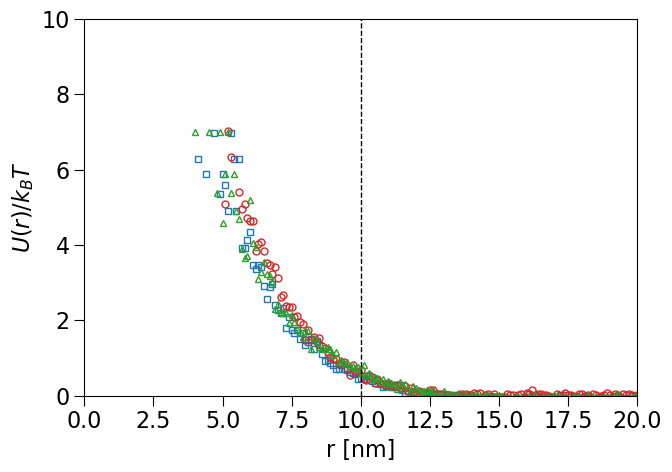

In [3]:
# --- Define the working directory ONCE ---
try:
    os.chdir(workdir)
except (NameError, FileNotFoundError):
    workdir = os.getcwd()

workdir = os.getcwd()
#-------------------------------------------

structures_list = ['mAb-1_7mM.pqr', 'mAb-1_57mM.pqr', 'mAb-2.pqr']

# (color, marker, label) per structure
style = {
    'mAb-1_7mM.pqr':  ('tab:blue',  's', 'mAb-1, I = 7 mM'),
    'mAb-1_57mM.pqr': ('tab:red',   'o', 'mAb-1, I = 57 mM'),
    'mAb-2.pqr':      ('tab:green', '^', 'mAb-2'),
}

plt.figure(figsize=(7, 5))
for structure in structures_list:
    name = os.path.splitext(structure)[0]
    r, g_r = np.loadtxt(os.path.join(name, 'rdf.dat'), unpack=True, usecols=(0, 1))
    color, marker, label = style[structure]
    # PMF = -ln g(r); g_bulk estimated from the last 100 bins
    plt.plot(r / 10, -np.log(g_r / np.mean(g_r[-100:])),
             marker=marker, markersize=5, color=color, label=label,
             fillstyle='none', linewidth=0)

plt.xlabel('r [nm]')
plt.ylabel(r'$U(r)/k_BT$')
plt.xlim(0, 20)
plt.ylim(0, 10)
plt.axvline(x=10, color='k', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()
